# Experiment B — Probe-specific reverse Reynolds prediction

**Question:** How much information about Reynolds can each probe's 27-frequency history provide independently, compared with the original four-probe GRU?

Train **five models** on the same `1211_1` healthy windows, evaluate on `1212_1` healthy windows: UUS, US, DS, DDS, and all four combined. Preserve the original compact-GRU architecture (frequency encoder → probe mean → GRU → current Reynolds); for single-probe inputs, the probe mean is the identity. **Do not reuse a combined-model checkpoint for single-probe inference**: retrain each model.

Outputs: `results/experiment_B_reverse_probe_models/`. This experiment does **not** establish which residuals cause Stage 2 false positives.

In [1]:
from pathlib import Path
import re, random, time, copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
SEED=42
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROBES=['UUS','US','DS','DDS']
TRAIN_RUN='1211_1';VAL_RUN='1212_1';WINDOW=40
EMBED_DIM=16;HIDDEN_DIM=24  # compact GRU configuration previously studied
EPOCHS=80;PATIENCE=12;LR=1e-3;BATCH=128
# For strictly holdout evaluation, early stopping uses a tail of the TRAIN run, never 1212_1.
TRAIN_FRACTION=.80
MAX_IMPORTANCE_WINDOWS=1200
PERMUTATION_REPEATS=3
root=Path.cwd().resolve()
PROJECT_ROOT=next((p for p in [root,root.parent] if (p/'data'/'2026-03-04').is_dir()),None)
if PROJECT_ROOT is None:raise FileNotFoundError('Run from project root or notebooks/')
DATA_DIR=PROJECT_ROOT/'data'/'2026-03-04'
OUTPUT=PROJECT_ROOT/'results'/'experiment_B_reverse_probe_models';OUTPUT.mkdir(parents=True,exist_ok=True)
print('Project:',PROJECT_ROOT,'Device:',DEVICE)

Project: /home/ubuntu/notebooks/Leak_Detection Device: cpu


## 1. Load and align spectra, Reynolds, and leak labels

Frequency columns are sorted numerically and checked across probes. Require exact timestamp alignment and Reynolds agreement. Do not silently truncate or fill missing values with zero.

In [2]:
def load_run(run):
    frames={p:pd.read_csv(DATA_DIR/f'{p}{run}.csv') for p in PROBES}
    ref=frames['UUS'];dt=pd.to_datetime(ref['Date-Time'],errors='raise').to_numpy()
    rc=next(c for c in ref if 'reynolds' in c.lower())
    re_ref=pd.to_numeric(ref[rc],errors='coerce').to_numpy(dtype=np.float32)
    leak_ref=pd.to_numeric(ref['Leak Event'],errors='coerce').to_numpy()
    if not np.isfinite(re_ref).all() or not np.isfinite(leak_ref).all():raise ValueError(f'{run}: missing Re/leak values')
    arrays=[];freq_ref=None
    for p,df in frames.items():
        if len(df)!=len(ref) or not np.array_equal(pd.to_datetime(df['Date-Time'],errors='raise').to_numpy(),dt):
            raise ValueError(f'{run}/{p}: timestamp alignment mismatch')
        c=next(c for c in df if 'reynolds' in c.lower())
        re=pd.to_numeric(df[c],errors='coerce').to_numpy(dtype=np.float32)
        if not np.allclose(re,re_ref,atol=1e-6,rtol=0):raise ValueError(f'{run}/{p}: Reynolds differs')
        if not np.array_equal(pd.to_numeric(df['Leak Event'],errors='coerce').to_numpy(),leak_ref):
            raise ValueError(f'{run}/{p}: Leak Event differs')
        pairs=[]
        for c in df:
            if 'ǀf' in c:
                token=c.split('ǀf',1)[1].replace('_','.')
                try:pairs.append((float(token),c))
                except ValueError:pass
        pairs.sort(key=lambda z:z[0]);freqs=[f for f,c in pairs]
        if len(freqs)!=27:raise ValueError(f'{run}/{p}: expected 27 frequencies, got {len(freqs)}')
        if freq_ref is None:freq_ref=freqs
        elif freqs!=freq_ref:raise ValueError(f'{run}/{p}: frequency order mismatch')
        x=df[[c for f,c in pairs]].apply(pd.to_numeric,errors='coerce').to_numpy(dtype=np.float32)
        if not np.isfinite(x).all():raise ValueError(f'{run}/{p}: non-finite spectra')
        arrays.append(x)
    return dict(X=np.stack(arrays,axis=1)/50.0,Re=re_ref/150.0,leak=leak_ref,dt=dt,freqs=freq_ref)
train=load_run(TRAIN_RUN);val=load_run(VAL_RUN)
print('Train:',train['X'].shape,'Evaluation:',val['X'].shape,'Frequencies:',train['freqs'])

Train: (10801, 4, 27) Evaluation: (10801, 4, 27) Frequencies: [25.0, 31.5, 40.0, 50.0, 63.0, 80.0, 100.0, 125.0, 160.0, 200.0, 250.0, 315.0, 400.0, 500.0, 630.0, 800.0, 1000.0, 1250.0, 1600.0, 2000.0, 2500.0, 3100.0, 4000.0, 5000.0, 6300.0, 8000.0, 10000.0]


## 2. Build 40-step healthy windows without crossing leak periods

Training/early-stop split uses **disjoint raw time blocks**, with no windows crossing the boundary. The validation run is untouched during model selection. This is a time-blocked holdout, not an independent-run early-stop set.

In [3]:
def endpoints(run,start,end):
    valid=(run['leak']==0).astype(int)
    ids=np.arange(max(start+WINDOW-1,WINDOW-1),end)
    prefix=np.r_[0,np.cumsum(valid)]
    return ids[(prefix[ids+1]-prefix[ids+1-WINDOW])==WINDOW]
cut=int(len(train['X'])*TRAIN_FRACTION)
train_ids=endpoints(train,0,cut)
es_ids=endpoints(train,cut,len(train['X']))
# Enforce windows entirely within early-stop segment.
es_ids=es_ids[es_ids-WINDOW+1>=cut]
val_ids=endpoints(val,0,len(val['X']))
print('Training',len(train_ids),'Early-stop',len(es_ids),'Evaluation',len(val_ids))
if min(map(len,[train_ids,es_ids,val_ids]))<100:raise ValueError('Insufficient healthy windows in a split')
class WindowDataset(Dataset):
    def __init__(self,run,ids,probe_indices):self.run=run;self.ids=np.asarray(ids);self.probe_indices=probe_indices
    def __len__(self):return len(self.ids)
    def __getitem__(self,i):
        end=int(self.ids[i]);x=self.run['X'][end-WINDOW+1:end+1][:,self.probe_indices,:].copy()
        return torch.from_numpy(x),torch.tensor(self.run['Re'][end],dtype=torch.float32)
class CompactSpectralGRU(nn.Module):
    def __init__(self,embed=EMBED_DIM,hidden=HIDDEN_DIM):
        super().__init__();self.encoder=nn.Sequential(nn.Linear(27,embed),nn.ReLU())
        self.gru=nn.GRU(embed,hidden,batch_first=True);self.head=nn.Linear(hidden,1)
    def forward(self,x):
        z=self.encoder(x).mean(dim=2) # original combined architecture; identity for one probe
        h,_=self.gru(z)
        return self.head(h[:,-1]).squeeze(-1)
def predict(model,ds):
    model.eval();out=[];targets=[]
    with torch.no_grad():
        for x,y in DataLoader(ds,batch_size=BATCH,shuffle=False):
            out.append(model(x.to(DEVICE)).cpu().numpy());targets.append(y.numpy())
    return np.concatenate(targets)*150,np.concatenate(out)*150

Training 6045 Early-stop 1483 Evaluation 7567


## 3. Train one GRU per probe plus the combined GRU

Same architecture and hyperparameters for a fair probe comparison. The combined model retains the original probe-mean encoder. Report MAE/RMSE/R² in physical Reynolds units.

,model,probes,n_test,MAE,RMSE,R2,params,epochs,seconds
1,US,US,7567,11.185,15.528,0.897,3497,23,37.971
4,combined,UUS+US+DS+DDS,7567,13.092,16.172,0.889,3497,25,44.662
0,UUS,UUS,7567,14.476,18.523,0.854,3497,35,58.335
3,DDS,DDS,7567,17.813,21.437,0.805,3497,20,33.282
2,DS,DS,7567,27.132,30.865,0.595,3497,19,30.332


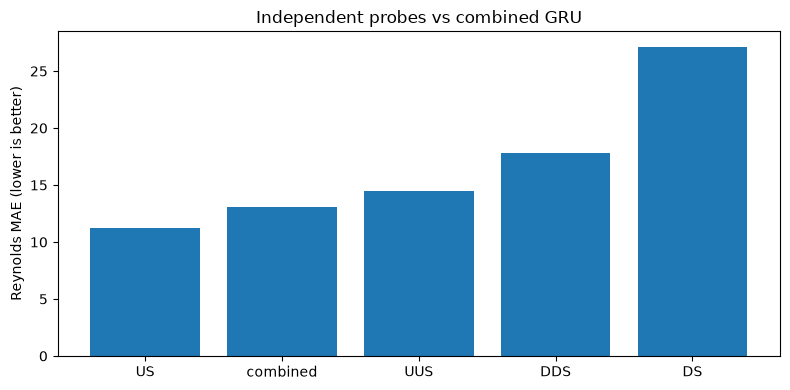

In [4]:
def train_model(probe_indices,label):
    torch.manual_seed(SEED)
    model=CompactSpectralGRU().to(DEVICE)
    tr=WindowDataset(train,train_ids,probe_indices);es=WindowDataset(train,es_ids,probe_indices)
    loader=DataLoader(tr,batch_size=BATCH,shuffle=True)
    opt=torch.optim.Adam(model.parameters(),lr=LR);loss_fn=nn.MSELoss()
    best=float('inf');best_state=None;wait=0;start=time.time()
    for epoch in range(EPOCHS):
        model.train();running=[]
        for x,y in loader:
            x=x.to(DEVICE);y=y.to(DEVICE);opt.zero_grad()
            loss=loss_fn(model(x),y);loss.backward();opt.step();running.append(float(loss.item()))
        yt,yp=predict(model,es);es_mse=float(np.mean((yt-yp)**2))
        if es_mse<best-1e-6:
            best=es_mse;best_state=copy.deepcopy(model.state_dict());wait=0
        else:
            wait+=1
            if wait>=PATIENCE:break
    model.load_state_dict(best_state)
    test=WindowDataset(val,val_ids,probe_indices);yt,yp=predict(model,test)
    params=sum(p.numel() for p in model.parameters())
    torch.save({'state_dict':model.cpu().state_dict(),'probes':[PROBES[i] for i in probe_indices],
                'embed_dim':EMBED_DIM,'hidden_dim':HIDDEN_DIM,'window':WINDOW,
                'spectrum_scale':50.,'reynolds_scale':150.,'train_run':TRAIN_RUN},OUTPUT/f'{label}_gru.pt')
    model.to(DEVICE)
    row=dict(model=label,probes='+'.join(PROBES[i] for i in probe_indices),n_test=len(yt),
             MAE=mean_absolute_error(yt,yp),RMSE=np.sqrt(mean_squared_error(yt,yp)),
             R2=r2_score(yt,yp),params=params,epochs=epoch+1,seconds=time.time()-start)
    pd.DataFrame({'timestamp':pd.to_datetime(val['dt'][val_ids]),'Re_actual':yt,'Re_predicted':yp}).to_csv(OUTPUT/f'{label}_predictions.csv',index=False)
    return model,row
models={};rows=[]
for p in PROBES:
    model,row=train_model([PROBES.index(p)],p);models[p]=model;rows.append(row)
model,row=train_model(list(range(4)),'combined');models['combined']=model;rows.append(row)
comparison=pd.DataFrame(rows).sort_values('MAE')
display(comparison.round(3));comparison.to_csv(OUTPUT/'probe_model_comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(comparison.model,comparison.MAE);ax.set_ylabel('Reynolds MAE (lower is better)');ax.set_title('Independent probes vs combined GRU');fig.tight_layout();fig.savefig(OUTPUT/'probe_comparison.png',dpi=160);plt.show()

## 4. Probe-specific frequency permutation importance

For each separately trained probe model, permute one frequency **across complete 40-step windows** (preserves each permuted sequence internal temporal structure) and compute increase in Reynolds MAE. This is model dependence, not physical importance and **not Stage 2 false-positive importance**. Permuting across windows can create off-distribution combinations; interpret cautiously.

,probe,frequency_hz,baseline_MAE,delta_MAE_mean,delta_MAE_std,repeats
35,US,160.0,11.201,10.686,0.239,3
84,DDS,50.0,17.823,10.379,0.289,3
8,UUS,160.0,14.482,9.562,0.480,3
62,DS,160.0,27.175,8.160,0.288,3
12,UUS,400.0,14.482,5.611,0.116,3
89,DDS,160.0,17.823,4.725,0.171,3
5,UUS,80.0,14.482,4.362,0.231,3
32,US,80.0,11.201,4.192,0.098,3
38,US,315.0,11.201,4.017,0.041,3
11,UUS,315.0,14.482,3.833,0.128,3


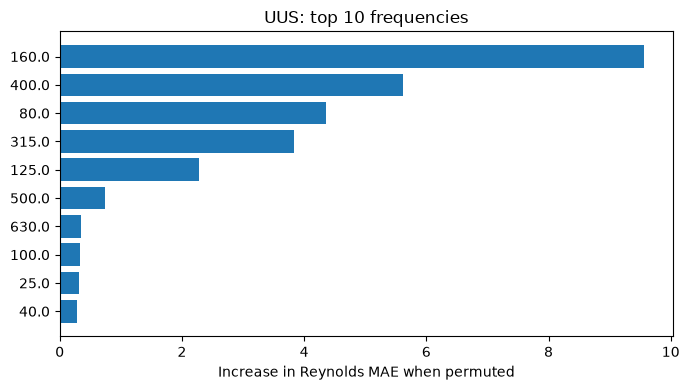

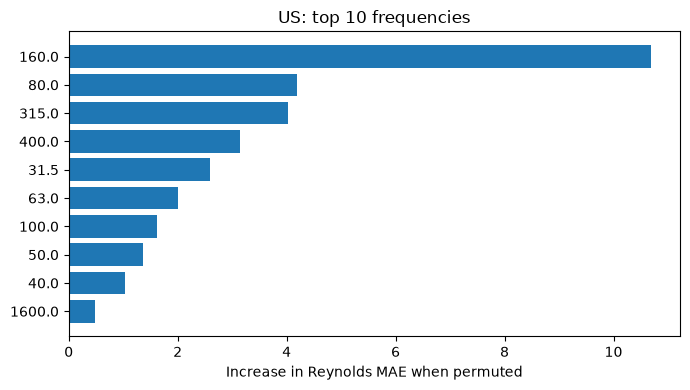

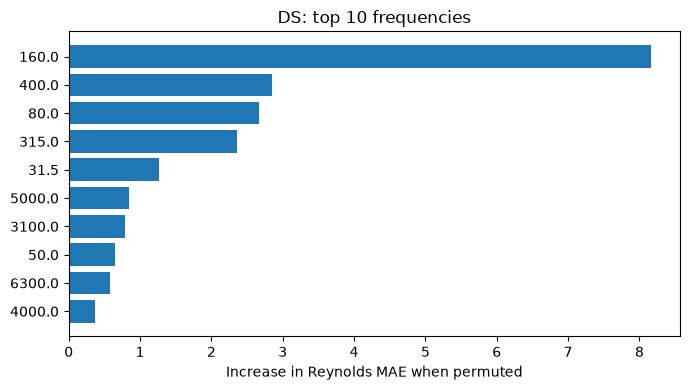

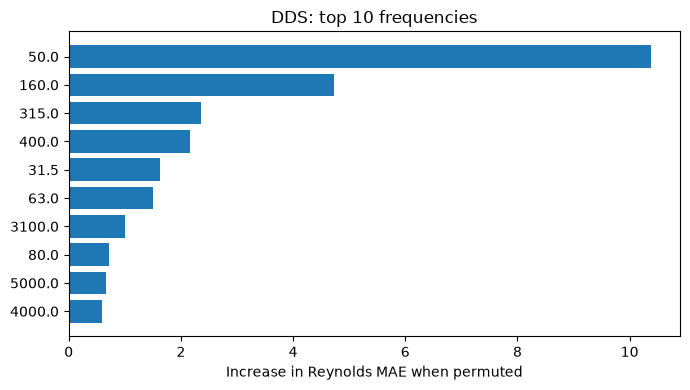

In [5]:
rng=np.random.default_rng(SEED)
importance_rows=[]
subset_ids=val_ids[np.linspace(0,len(val_ids)-1,min(MAX_IMPORTANCE_WINDOWS,len(val_ids)),dtype=int)]
for probe in PROBES:
    k=PROBES.index(probe);ds=WindowDataset(val,subset_ids,[k]);model=models[probe]
    # Small bounded diagnostic set; memory cost <= 1200 × 40 × 27 floats per probe.
    X=np.stack([ds[i][0].numpy() for i in range(len(ds))]);y=val['Re'][subset_ids]*150
    def mae_for(arr):
        model.eval();pred=[]
        with torch.no_grad():
            for i in range(0,len(arr),BATCH):pred.append(model(torch.from_numpy(arr[i:i+BATCH]).to(DEVICE)).cpu().numpy())
        return mean_absolute_error(y,np.concatenate(pred)*150)
    base_mae=mae_for(X)
    for fi,f in enumerate(val['freqs']):
        deltas=[]
        for rep in range(PERMUTATION_REPEATS):
            z=X.copy();perm=rng.permutation(len(z));z[:,:,0,fi]=X[perm,:,0,fi]
            deltas.append(mae_for(z)-base_mae)
        importance_rows.append(dict(probe=probe,frequency_hz=f,baseline_MAE=base_mae,
                                    delta_MAE_mean=float(np.mean(deltas)),delta_MAE_std=float(np.std(deltas)),
                                    repeats=PERMUTATION_REPEATS))
importance=pd.DataFrame(importance_rows).sort_values('delta_MAE_mean',ascending=False)
display(importance.groupby('probe',group_keys=False).head(8).round(3))
importance.to_csv(OUTPUT/'probe_frequency_importance.csv',index=False)
for probe in PROBES:
    d=importance[importance.probe.eq(probe)].head(10).sort_values('delta_MAE_mean')
    fig,ax=plt.subplots(figsize=(7,4));ax.barh(d.frequency_hz.astype(str),d.delta_MAE_mean)
    ax.set_xlabel('Increase in Reynolds MAE when permuted');ax.set_title(f'{probe}: top 10 frequencies')
    fig.tight_layout();fig.savefig(OUTPUT/f'{probe}_frequency_importance.png',dpi=160);plt.show()

## 5. Decision guide and limitations

- If US and DS individually predict Reynolds well, opposite Stage 1 residual biases are **not** explained simply by an absence of Reynolds information.
- If one probe performs poorly, it indicates weaker independently decodable Reynolds signal **for this GRU**; it does not prove Stage 1 must fail there.
- A combined model can outperform each probe because it aggregates complementary signals; averaging embeddings does not average raw spectra.
- **Do not rank Stage 2 false-positive drivers using reverse permutation importance.** That requires Stage 2 residual interventions (separate Experiment C).
- Single training run and evaluation run, autocorrelated overlapping windows, shared Reynolds target, and potential sensor/run differences limit generalization.
- Train/early-stop split is time-blocked within a run; the 1212_1 evaluation run is not used for tuning.